# 4 · Key-value databases: fast for the questions you planned

**The question:** when is a key-value store like DynamoDB the right home for data, and what does it
cost you?

**What a key-value store is:** every item has a *key*; give the key, get the item back, in a few
milliseconds no matter how big the table gets. A second part of the key (the *sort key*) keeps items
in order under the first, so "this user's items, newest first" is also one fast request. Any other
question means reading the whole table.

**Setup:** DynamoDB Local (AWS's official emulator) in Docker, holding the SciFact abstracts again
plus a synthetic reading history: 1,000 users x 50 views, popular abstracts read more often.

In [1]:
%matplotlib inline
import os, json
os.chdir('..')  # run from the project root so data/ and results/ resolve
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from oslab import plot, stack
plot.style()
pd.set_option('display.width', 160)
assert stack.is_up(), 'start the stack first: docker compose up -d'

from oslab import kv

## 1 · Designing keys from the questions

| Table | Partition key | Sort key | Question it answers fast |
|---|---|---|---|
| `kv-docs` | `id` | | "give me abstract 4983" |
| `kv-views` | `user` | `viewed_at` | "what did user u0042 read lately?" |

In Postgres you design tables around the *data* and add indexes later. In DynamoDB you design keys
around the *questions*, up front.

In [2]:
print('views table:', kv.table_stats())
kv.ddb().Table(kv.VIEWS).get_item(Key={'user': 'u0042', 'viewed_at': kv.ddb().Table(kv.VIEWS).query(
    KeyConditionExpression=kv.Key('user').eq('u0042'), Limit=1)['Items'][0]['viewed_at']})['Item']

views table: {'items': 50000, 'bytes': 3070813}


{'doc': '21272977',
 'seconds': Decimal('240'),
 'viewed_at': '2026-09-22T09:40:04Z#00',
 'user': 'u0042'}

## 2 · Each question's cost

DynamoDB bills by **read capacity units**: one unit is roughly one 4 KB read. The emulator reports
them exactly as AWS would, so we can count the cost of each question (the timings are a local
emulator's and don't transfer to AWS; the units do).

The question the table was *not* designed for, "who read abstract X?", has no key. The only way is
a **Scan**: read every item and filter afterwards. The fix is a **global secondary index (GSI)**, a
second copy of the keys organised by `doc`.

In [3]:
p = json.load(open('results/kv-patterns.json'))
labels = {'get_doc': 'get one abstract by id', 'user_recent': "a user's last 20 reads",
          'readers_scan': 'who read abstract X? (scan)', 'readers_gsi': 'who read abstract X? (GSI)'}
t = pd.DataFrame(p['patterns']).assign(question=lambda d: d.pattern.map(labels))
t[['question', 'items', 'read_units', 'usd_per_million', 'postgres_ms']]

,question,items,read_units,usd_per_million,postgres_ms
0,get one abstract by id,1,0.5,0.06,0.19
1,a user's last 20 reads,20,0.5,0.06,0.13
2,who read abstract X? (scan),2087,376.0,47.00,4.86
3,who read abstract X? (GSI),2087,13.0,1.62,NaN


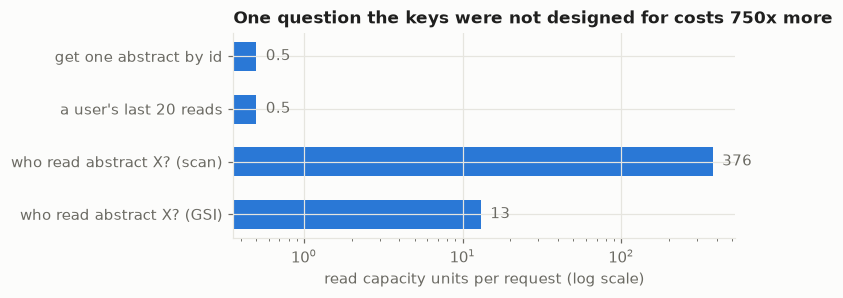

In [4]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(t.question[::-1], t.read_units[::-1], color=plot.SERIES[0], height=0.55)
ax.set_xscale('log'); ax.set_xlabel('read capacity units per request (log scale)')
ax.set_title('One question the keys were not designed for costs 750x more')
for y, v in enumerate(t.read_units[::-1]):
    ax.text(v * 1.15, y, f'{v:g}', va='center', color=plot.MUTED)
plt.tight_layout()

**Reading it:** a keyed read costs 0.5 units whatever the table size. The scan cost 376 units for a
3 MB table, and **grows with the table**: at 3 GB it would be about 1,000x more again. The GSI brings
the same question down to 13 units, but it is a second copy of the keys: more storage, more write
cost, and it is updated *eventually* (a moment after the main table).

The dollar column uses the on-demand list price of $0.125 per million read
units (us-east-1, not re-verified this session).

Postgres answers all of these, including "who read X?", with one SQL query, and an index can be added
later without redesigning anything. That flexibility is why it's the default; DynamoDB's trade is
predictable speed and cost at any scale for the questions you planned, with no server to run.

## 3 · Keeping a search index in sync: the change feed

DynamoDB can't search text. The standard pattern: turn on **DynamoDB Streams** (a log of every insert,
update and delete), and have a small function apply each change to OpenSearch. On AWS that function
is a Lambda; locally, `kv.StreamSync` polls the stream.

**Known answer:** after syncing, OpenSearch must hold exactly the same items with the same text.

In [5]:
sync = json.load(open('results/kv-sync.json'))
print('after the initial load:      ', sync['initial'])
print('after one edit and one delete:', sync['after_edit_delete'])
print('write -> searchable delay (ms):', {k: round(v) for k, v in sync['lag_ms'].items()})

after the initial load:       {'dynamodb': 5183, 'opensearch': 5183, 'identical': True}
after one edit and one delete: {'dynamodb': 5182, 'opensearch': 5182, 'identical': True}
write -> searchable delay (ms): {'p50': 22, 'p95': 38, 'max': 39, 'poll_every_ms': 200}


The copy was exact, and edits and deletes flowed through. The delay here (about 20 ms) is a local
poller's; on AWS, the stream-to-Lambda hop typically adds up to about a second. Either way the search
index is **eventually consistent**: a user who saves and immediately searches may not see their change.
Applications either accept that or read the item back by key.

## Choosing between the three

| Need | Best fit |
|---|---|
| Relational data, ad-hoc questions, transactions | **Postgres** |
| Known access patterns, any scale, no server, pay per request | **DynamoDB** |
| Ranked text search, log analytics, vector/hybrid search | **OpenSearch**, fed from one of the above |

**Industry uses of key-value stores:** shopping carts, user sessions and profiles, game state,
device telemetry by device and time, feature stores for ML models.